In [1]:
import sys
import os

# 1. Determine the current working directory (which is inside 'notebooks')
current_dir = os.getcwd()

# 2. Get the parent directory (which is the project root, containing 'data' and 'notebooks')
parent_dir = os.path.abspath(os.path.join(current_dir, '..'))

# 3. Add the project root to the system path
sys.path.append(parent_dir)

print(f"Successfully added {parent_dir} to sys.path")


Successfully added /Users/nicholaskryger/code/POD to sys.path


Using device cpu


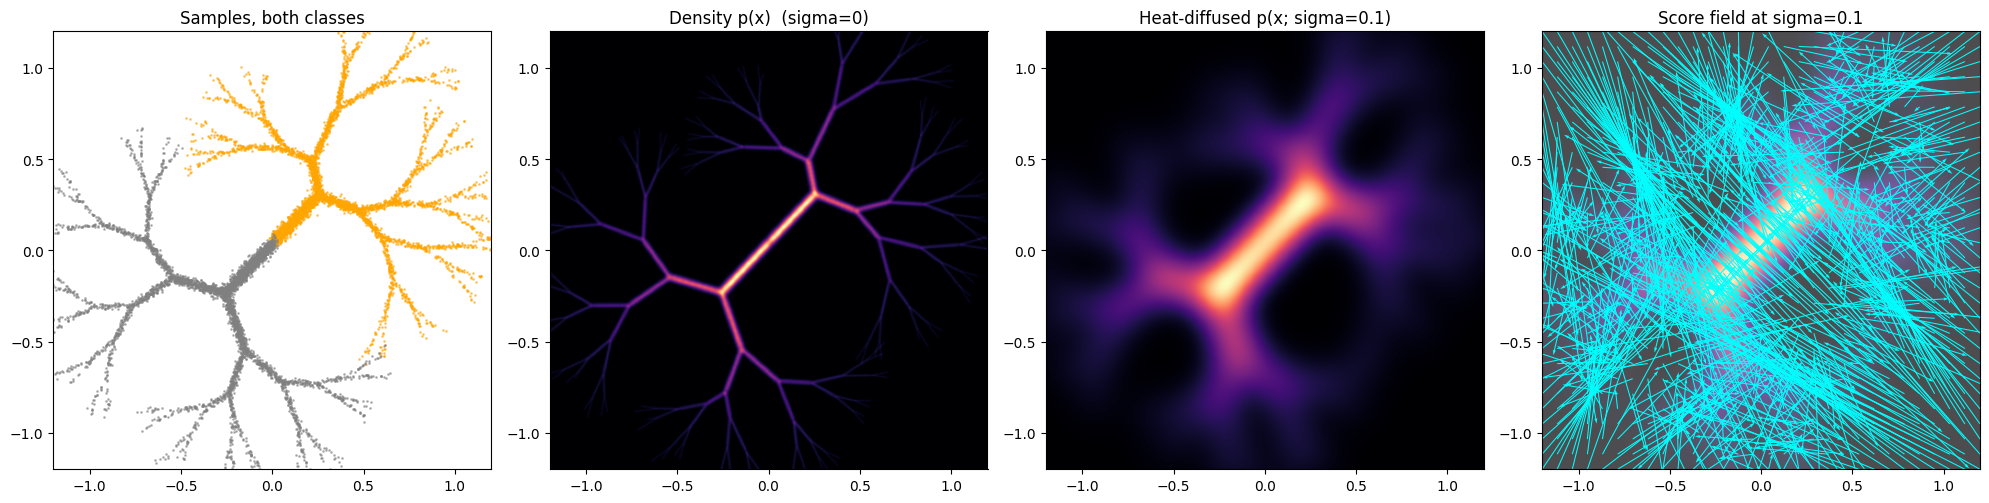

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from data.tree import gt  # assuming the file is named toy_example.py

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device {device}")

# ---------- Get the distribution ----------
dist_A  = gt(classes='A',  device=device)
dist_B  = gt(classes='B',  device=device)
dist_AB = gt(classes='AB', device=device)

# ---------- Draw samples at sigma = 0 (clean) ----------
torch.manual_seed(0)
samples_A = dist_A.sample((5000,)).cpu().numpy()
samples_B = dist_B.sample((5000,)).cpu().numpy()

# ---------- Evaluate density on a grid ----------
res = 400
extent = 1.2
x = torch.linspace(-extent, extent, res, device=device)
y = torch.linspace(-extent, extent, res, device=device)
gx, gy = torch.meshgrid(x, y, indexing='xy')
grid = torch.stack([gx, gy], dim=-1)   # [res, res, 2]

pdf_clean = dist_AB.pdf(grid, sigma=0.0).cpu().numpy()
pdf_noisy = dist_AB.pdf(grid, sigma=0.1).cpu().numpy()   # heat-diffused

# ---------- Evaluate score field on a coarser grid ----------
sres = 30
sx = torch.linspace(-extent, extent, sres, device=device)
sy = torch.linspace(-extent, extent, sres, device=device)
sgx, sgy = torch.meshgrid(sx, sy, indexing='xy')
sgrid = torch.stack([sgx, sgy], dim=-1)
score = dist_AB.score(sgrid, sigma=0.1).cpu().numpy()    # [sres, sres, 2]

# ---------- Plot ----------
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].scatter(samples_A[:, 0], samples_A[:, 1], s=1, c='orange', alpha=0.5)
axes[0].scatter(samples_B[:, 0], samples_B[:, 1], s=1, c='gray',   alpha=0.5)
axes[0].set_title('Samples, both classes')
axes[0].set_aspect('equal')

axes[1].imshow(pdf_clean, extent=[-extent, extent, -extent, extent],
               origin='lower', cmap='magma')
axes[1].set_title('Density p(x)  (sigma=0)')

axes[2].imshow(pdf_noisy, extent=[-extent, extent, -extent, extent],
               origin='lower', cmap='magma')
axes[2].set_title('Heat-diffused p(x; sigma=0.1)')

axes[3].imshow(pdf_noisy, extent=[-extent, extent, -extent, extent],
               origin='lower', cmap='magma', alpha=0.7)
axes[3].quiver(sgx.cpu(), sgy.cpu(), score[..., 0], score[..., 1],
               color='cyan', scale=50)
axes[3].set_title('Score field at sigma=0.1')
axes[3].set_aspect('equal')

for ax in axes:
    ax.set_xlim(-extent, extent); ax.set_ylim(-extent, extent)

plt.tight_layout()
plt.savefig('tree_distribution.png', dpi=150)
plt.show()